Lab 5: Hierarchical and DBSCAN Clustering
Student: Sebastian C
Course: MSCS 634
Assignment: Lab 5 - Hierarchical and DBSCAN Clustering
Date: 11/1/2026


Step 1: Data Preparation and Exploration
In this section, the Wine dataset is loaded from the sklearn.datasets module and converted into a pandas DataFrame. The structure, summary statistics, class distribution, and data quality are examined before the features are standardized for clustering.

The target labels are retained for later evaluation of the clustering results, but they are not included as input features when fitting the clustering algorithms.

In [1]:
# Import the libraries required for data preparation and exploration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Improve the readability of pandas outputs
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Set a consistent plot style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


1.1 Loading the Wine Dataset
The Wine dataset is loaded using load_wine() from scikit-learn. The dataset includes numerical measurements derived from chemical analyses of wines and a target value indicating the known wine class.

In [2]:
# Load the Wine dataset as pandas objects
wine = load_wine(as_frame=True)

# Separate the clustering features from the known class labels
X = wine.data.copy()
y = wine.target.copy()

# Create a complete DataFrame for exploration
wine_df = X.copy()
wine_df["target"] = y
wine_df["target_name"] = wine_df["target"].map(
    dict(enumerate(wine.target_names))
)

print("Wine dataset loaded successfully.")
print(f"Number of observations: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Target classes: {list(wine.target_names)}")

Wine dataset loaded successfully.
Number of observations: 178
Number of features: 13
Target classes: ['class_0', 'class_1', 'class_2']


1.2 Initial Dataset Examination
The first five observations are displayed to verify that the dataset was loaded correctly and to examine the feature and target columns.

In [3]:
# Display the first five observations
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [4]:
# Display the dimensions of the complete DataFrame
print(f"DataFrame shape: {wine_df.shape}")

# Display column names
print("\nColumn names:")
print(wine_df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
wine_df.info()

DataFrame shape: (178, 15)

Column names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target', 'target_name']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   p

1.3 Descriptive Statistics
Descriptive statistics are calculated to examine the central tendency, dispersion, and range of each numerical feature. Differences in the feature scales would indicate that standardization is necessary before applying distance-based clustering algorithms.

In [5]:
# Display descriptive statistics for the numerical features
X.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [6]:
# Check for missing values in each feature
missing_values = X.isnull().sum()

print("Missing values by feature:")
print(missing_values)

print(f"\nTotal missing values: {missing_values.sum()}")
print(f"Number of duplicate rows: {X.duplicated().sum()}")

Missing values by feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0
Number of duplicate rows: 0


In [7]:
# Examine the distribution of the known target classes
class_distribution = (
    wine_df["target_name"]
    .value_counts()
    .sort_index()
    .rename_axis("Wine Class")
    .reset_index(name="Number of Samples")
)

class_distribution

,Wine Class,Number of Samples
0,class_0,59
1,class_1,71
2,class_2,48


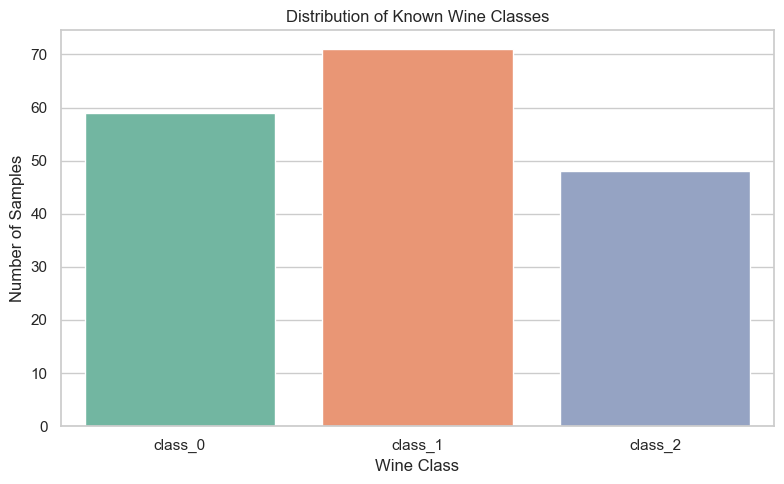

In [8]:
# Visualize the distribution of the known wine classes
plt.figure(figsize=(8, 5))

sns.countplot(
    data=wine_df,
    x="target_name",
    hue="target_name",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Known Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


1.4 Feature Standardization
The Wine dataset contains features measured on substantially different scales. Because Hierarchical Clustering and DBSCAN rely on distances between observations, features with larger numeric ranges could have an unintended influence on the clustering results.

StandardScaler is therefore used to transform each feature so that it has a mean approximately equal to zero and a standard deviation approximately equal to one.

In [9]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler to the feature data and transform the features
X_scaled_array = scaler.fit_transform(X)

# Convert the standardized array back into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X.columns,
    index=X.index
)

print("Feature standardization completed.")
print(f"Standardized dataset shape: {X_scaled.shape}")

X_scaled.head()

Feature standardization completed.
Standardized dataset shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [10]:
# Verify the means and standard deviations after standardization
standardization_check = pd.DataFrame({
    "Mean After Standardization": X_scaled.mean(),
    "Standard Deviation After Standardization": X_scaled.std(ddof=0)
})

standardization_check.round(4)

,Mean After Standardization,Standard Deviation After Standardization
alcohol,-0.0,1.0
malic_acid,-0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,-0.0,1.0
magnesium,-0.0,1.0
total_phenols,0.0,1.0
flavanoids,-0.0,1.0
nonflavanoid_phenols,0.0,1.0
proanthocyanins,-0.0,1.0
color_intensity,0.0,1.0


In [11]:
print(
    "Largest absolute standardized mean:",
    round(X_scaled.mean().abs().max(), 10)
)

print(
    "Largest deviation from unit standard deviation:",
    round((X_scaled.std(ddof=0) - 1).abs().max(), 10)
)

Largest absolute standardized mean: 0.0
Largest deviation from unit standard deviation: 0.0


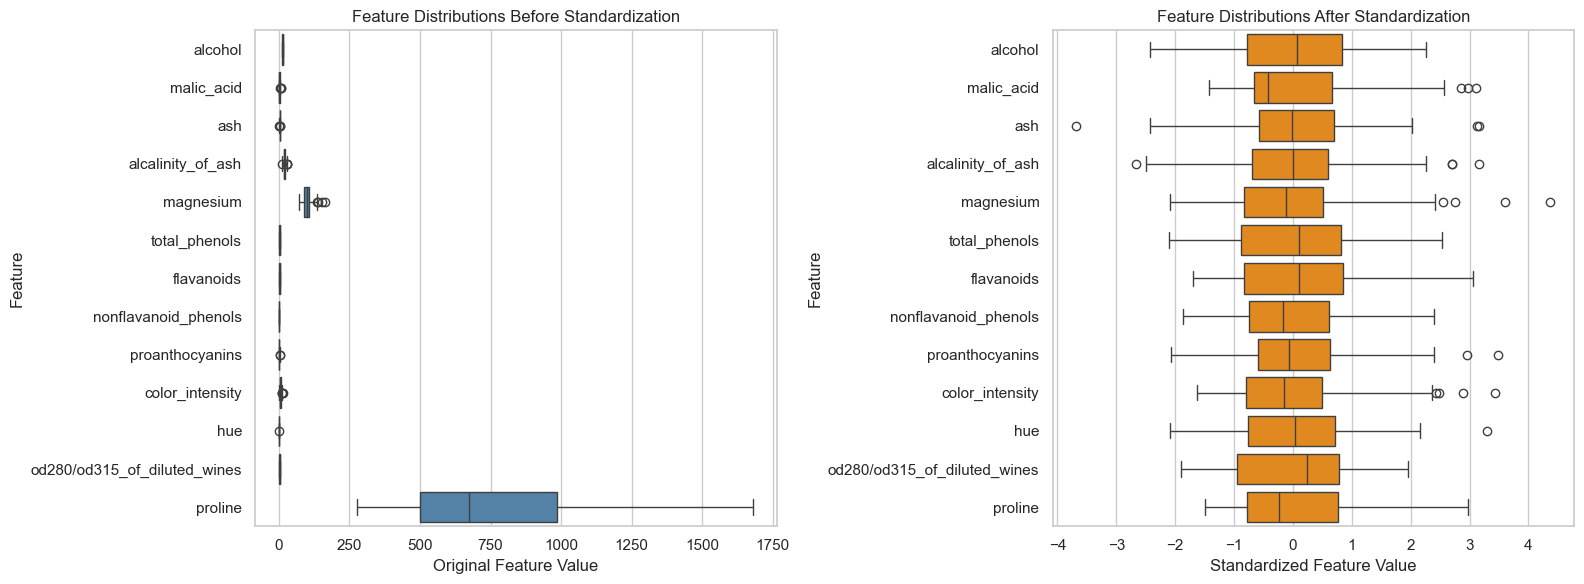

In [12]:
# Compare feature distributions before and after standardization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=X, orient="h", ax=axes[0], color="steelblue")
axes[0].set_title("Feature Distributions Before Standardization")
axes[0].set_xlabel("Original Feature Value")
axes[0].set_ylabel("Feature")

sns.boxplot(data=X_scaled, orient="h", ax=axes[1], color="darkorange")
axes[1].set_title("Feature Distributions After Standardization")
axes[1].set_xlabel("Standardized Feature Value")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

Step 1 Observations
The Wine dataset contains 178 observations and 13 numerical features. The known target variable identifies three wine classes and is retained for later evaluation, but it will not be supplied to the clustering algorithms.

The initial examination included the first five records, dataset dimensions, data types, descriptive statistics, missing-value counts, duplicate-row counts, and the known class distribution. The descriptive statistics showed that the features have substantially different numeric ranges. Consequently, using the original measurements directly could cause features with larger values to exert greater influence on distance-based clustering.

To address this issue, the 13 input features were transformed using StandardScaler. The standardized features have means approximately equal to zero and standard deviations approximately equal to one. The standardized DataFrame, X_scaled, will be used as the input for Hierarchical Clustering and DBSCAN in the subsequent sections.

Step 2: Hierarchical Clustering
Agglomerative Hierarchical Clustering is applied to the standardized Wine dataset. Multiple values of n_clusters are evaluated to determine how the number of clusters affects the clustering results. The clusters are then visualized using Principal Component Analysis, and a dendrogram is used to examine the hierarchical relationships among observations.

In [13]:
# Import libraries for Hierarchical Clustering and visualization
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

print("Step 2 libraries imported successfully.")

Step 2 libraries imported successfully.


2.1 Testing Different Numbers of Clusters
Agglomerative Clustering is evaluated using cluster counts ranging from two through six. Ward linkage is used because it seeks to minimize the variance within each cluster. The Silhouette Score is calculated for each result, with a higher score indicating better cluster separation and cohesion.

In [14]:
# Test different values of n_clusters
hierarchical_results = []

for n_clusters in range(2, 7):
    hierarchical_model = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage="ward"
    )
    
    cluster_labels = hierarchical_model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    
    hierarchical_results.append({
        "Number of Clusters": n_clusters,
        "Silhouette Score": score
    })

# Convert the results into a DataFrame
hierarchical_results_df = pd.DataFrame(hierarchical_results)

# Display the scores rounded to four decimal places
hierarchical_results_df.round(4)

,Number of Clusters,Silhouette Score
0,2,0.2670
1,3,0.2774
2,4,0.2258
3,5,0.1867
4,6,0.1797


In [15]:
# Identify the cluster count with the highest Silhouette Score
best_result_index = hierarchical_results_df[
    "Silhouette Score"
].idxmax()

best_n_clusters = int(
    hierarchical_results_df.loc[
        best_result_index,
        "Number of Clusters"
    ]
)

best_silhouette_score = hierarchical_results_df.loc[
    best_result_index,
    "Silhouette Score"
]

print(f"Best number of clusters: {best_n_clusters}")
print(f"Best Silhouette Score: {best_silhouette_score:.4f}")

Best number of clusters: 3
Best Silhouette Score: 0.2774


2.2 Final Hierarchical Clustering Model
The final Agglomerative Clustering model is fitted using the number of clusters that produced the highest Silhouette Score among the tested values.

In [16]:
# Create and fit the final Hierarchical Clustering model
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_n_clusters,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

# Add the cluster assignments to the exploratory DataFrame
wine_df["hierarchical_cluster"] = hierarchical_labels

print("Final Hierarchical Clustering model fitted successfully.")
print(f"Number of clusters formed: {len(np.unique(hierarchical_labels))}")

print("\nNumber of observations in each cluster:")
print(
    wine_df["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)


Final Hierarchical Clustering model fitted successfully.
Number of clusters formed: 3

Number of observations in each cluster:
hierarchical_cluster
0    58
1    56
2    64
Name: count, dtype: int64


2.3 Cluster Visualization
Principal Component Analysis is used to reduce the 13 standardized features to two principal components. This reduction makes it possible to display the Hierarchical Clustering assignments in a two-dimensional scatter plot. PCA is used only for visualization; the clustering model itself is fitted using all 13 standardized features.

In [17]:
# Reduce the standardized features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame containing the two principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"],
    index=X_scaled.index
)

# Add the Hierarchical Clustering assignments
pca_df["Hierarchical Cluster"] = hierarchical_labels.astype(str)

print("Explained variance by each principal component:")
print(f"PC1: {pca.explained_variance_ratio_[0]:.4f}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.4f}")

print(
    "Total explained variance:",
    f"{pca.explained_variance_ratio_.sum():.4f}"
)

pca_df.head()

Explained variance by each principal component:
PC1: 0.3620
PC2: 0.1921
Total explained variance: 0.5541


,Principal Component 1,Principal Component 2,Hierarchical Cluster
0,3.316751,1.443463,2
1,2.209465,-0.333393,2
2,2.516740,1.031151,2
3,3.757066,2.756372,2
4,1.008908,0.869831,2


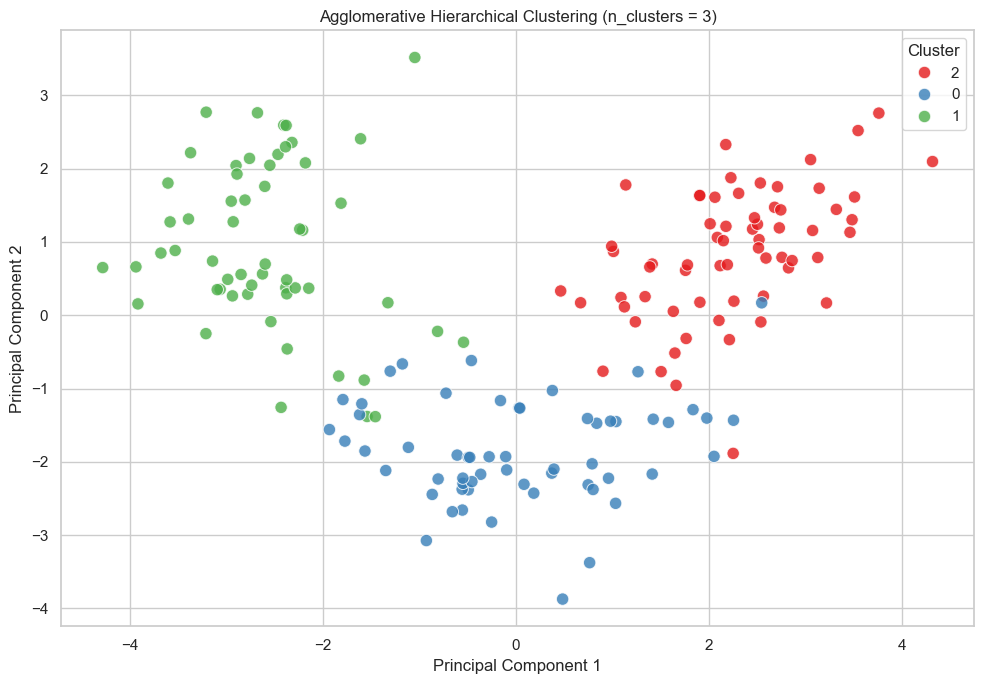

In [18]:
# Visualize the Hierarchical Clustering results
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Hierarchical Cluster",
    palette="Set1",
    s=80,
    alpha=0.8
)

plt.title(
    f"Agglomerative Hierarchical Clustering "
    f"(n_clusters = {best_n_clusters})"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

2.4 Hierarchical Clustering Dendrogram
A dendrogram displays the sequence in which observations and groups of observations are merged. Lower merge heights indicate greater similarity, while higher merge heights indicate that less similar groups are being combined.

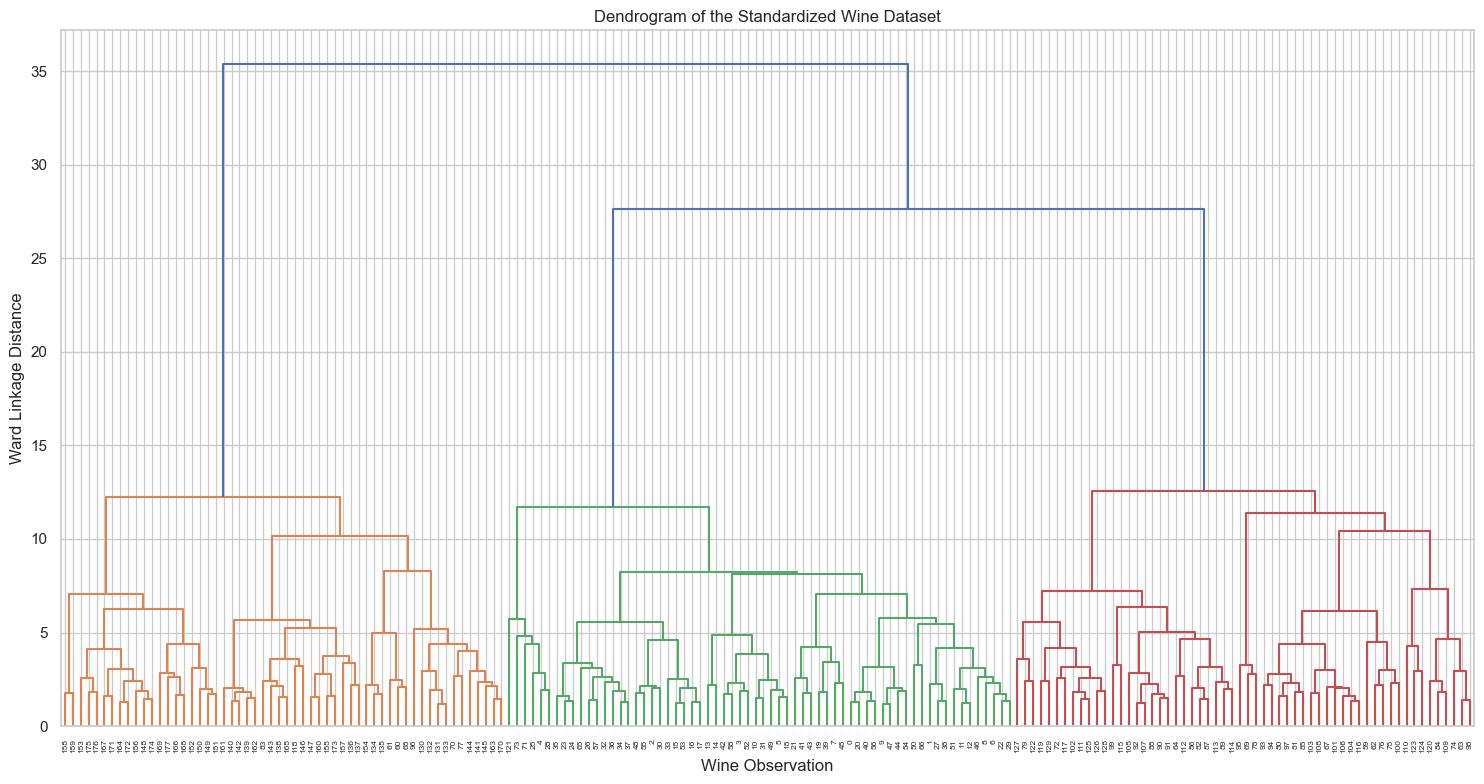

In [19]:
# Calculate the hierarchical linkage matrix using Ward linkage
linkage_matrix = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

# Generate the dendrogram
plt.figure(figsize=(15, 8))

dendrogram(
    linkage_matrix,
    leaf_rotation=90,
    leaf_font_size=6
)

plt.title("Dendrogram of the Standardized Wine Dataset")
plt.xlabel("Wine Observation")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

Step 2 Observations
Agglomerative Hierarchical Clustering was applied to all 13 standardized features using Ward linkage. Cluster counts from two through six were tested, and the Silhouette Score was calculated for each result. The cluster count with the highest Silhouette Score was selected for the final Hierarchical Clustering model.

The resulting clusters were visualized after reducing the standardized features to two principal components. The PCA scatter plot showed the general separation and overlap among the assigned clusters. Because PCA was used only for visualization, the two-dimensional plot does not represent all of the information used by the clustering model.

The dendrogram illustrated how individual wine observations were progressively merged into larger groups. Merges at lower linkage distances represented more similar observations, while merges occurring at greater heights represented the combination of less similar groups. Large vertical gaps near the top of the dendrogram indicated possible separation between the dataset's major cluster structures.

Step 3: DBSCAN Clustering
DBSCAN is applied to the standardized Wine dataset to identify dense groups of observations and potential noise points. Multiple combinations of eps and min_samples are tested to examine how these parameters affect the number of clusters and noise observations.

The clustering results are evaluated using the Silhouette Score, Homogeneity Score, and Completeness Score. The known wine labels are used only to evaluate the resulting clusters and are not supplied to DBSCAN during model fitting.

In [20]:
# Import DBSCAN and the required evaluation metrics
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)

print("Step 3 libraries imported successfully.")

Step 3 libraries imported successfully.


3.1 DBSCAN Parameter Experiment
Different combinations of eps and min_samples are tested. A smaller eps value generally produces more noise because observations must be closer together to be considered neighbors. A larger eps value can connect more observations and may merge separate groups.

The min_samples parameter controls the number of neighboring observations required to form a dense region. Increasing this value makes the density requirement more restrictive.

In [21]:
# Parameter values to test
eps_values = [1.5, 2.0, 2.5, 3.0]
min_samples_values = [3, 5, 10]

# Store the results from each parameter combination
dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan_model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )
        
        dbscan_labels = dbscan_model.fit_predict(X_scaled)
        
        # Identify cluster labels other than the noise label (-1)
        cluster_labels = set(dbscan_labels)
        cluster_labels.discard(-1)
        
        number_of_clusters = len(cluster_labels)
        number_of_noise_points = np.sum(dbscan_labels == -1)
        
        # Silhouette Score requires at least two non-noise clusters
        non_noise_mask = dbscan_labels != -1
        non_noise_labels = dbscan_labels[non_noise_mask]
        
        if (
            number_of_clusters >= 2
            and len(np.unique(non_noise_labels)) >= 2
        ):
            silhouette = silhouette_score(
                X_scaled.loc[non_noise_mask],
                non_noise_labels
            )
        else:
            silhouette = np.nan
        
        # Evaluate all DBSCAN labels, including the noise label
        homogeneity = homogeneity_score(y, dbscan_labels)
        completeness = completeness_score(y, dbscan_labels)
        
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Number of Clusters": number_of_clusters,
            "Noise Points": number_of_noise_points,
            "Silhouette Score": silhouette,
            "Homogeneity Score": homogeneity,
            "Completeness Score": completeness
        })

# Convert the results into a DataFrame
dbscan_results_df = pd.DataFrame(dbscan_results)

# Display the parameter experiment results
dbscan_results_df.round(4)

,eps,min_samples,Number of Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,1.5,3,8,147,0.3311,0.1892,0.2510
1,1.5,5,0,178,NaN,0.0000,1.0000
2,1.5,10,0,178,NaN,0.0000,1.0000
3,2.0,3,5,64,0.2113,0.4423,0.3724
4,2.0,5,5,85,0.2405,0.3624,0.3247
5,2.0,10,1,139,NaN,0.2887,0.5963
6,2.5,3,1,23,NaN,0.0668,0.1885
7,2.5,5,1,24,NaN,0.0576,0.1581
8,2.5,10,2,32,0.3228,0.5045,0.5604
9,3.0,3,2,7,0.2392,0.0311,0.1347


In [22]:
# Display a concise parameter comparison
parameter_comparison = dbscan_results_df[
    [
        "eps",
        "min_samples",
        "Number of Clusters",
        "Noise Points",
        "Silhouette Score"
    ]
].copy()

parameter_comparison.round(4)

,eps,min_samples,Number of Clusters,Noise Points,Silhouette Score
0,1.5,3,8,147,0.3311
1,1.5,5,0,178,NaN
2,1.5,10,0,178,NaN
3,2.0,3,5,64,0.2113
4,2.0,5,5,85,0.2405
5,2.0,10,1,139,NaN
6,2.5,3,1,23,NaN
7,2.5,5,1,24,NaN
8,2.5,10,2,32,0.3228
9,3.0,3,2,7,0.2392


3.2 Selection of the DBSCAN Parameters
The final parameter combination is selected from the results that produced at least two non-noise clusters and a valid Silhouette Score. Among those valid results, the combination with the highest Silhouette Score is selected.

In [24]:
# Keep only parameter combinations with a valid Silhouette Score
valid_dbscan_results = dbscan_results_df.dropna(
    subset=["Silhouette Score"]
).copy()

if valid_dbscan_results.empty:
    raise ValueError(
        "None of the tested parameter combinations produced at least "
        "two non-noise clusters. Try additional eps values."
    )

# Find the valid combination with the highest Silhouette Score
best_dbscan_index = valid_dbscan_results[
    "Silhouette Score"
].idxmax()

best_dbscan_result = dbscan_results_df.loc[best_dbscan_index]

best_eps = float(best_dbscan_result["eps"])
best_min_samples = int(best_dbscan_result["min_samples"])

print(f"Selected eps: {best_eps}")
print(f"Selected min_samples: {best_min_samples}")
print(
    "Number of clusters:",
    int(best_dbscan_result["Number of Clusters"])
)
print(
    "Number of noise points:",
    int(best_dbscan_result["Noise Points"])
)
print(
    "Silhouette Score:",
    f"{best_dbscan_result['Silhouette Score']:.4f}"
)
print(
    "Homogeneity Score:",
    f"{best_dbscan_result['Homogeneity Score']:.4f}"
)
print(
    "Completeness Score:",
    f"{best_dbscan_result['Completeness Score']:.4f}"
)

Selected eps: 1.5
Selected min_samples: 3
Number of clusters: 8
Number of noise points: 147
Silhouette Score: 0.3311
Homogeneity Score: 0.1892
Completeness Score: 0.2510


In [25]:
# Fit the final DBSCAN model using the selected parameters
best_dbscan_model = DBSCAN(
    eps=best_eps,
    min_samples=best_min_samples
)

best_dbscan_labels = best_dbscan_model.fit_predict(X_scaled)

# Save the cluster assignments in the exploratory DataFrame
wine_df["dbscan_cluster"] = best_dbscan_labels

# Count regular clusters and noise points
unique_dbscan_labels = set(best_dbscan_labels)
unique_dbscan_labels.discard(-1)

dbscan_cluster_count = len(unique_dbscan_labels)
dbscan_noise_count = np.sum(best_dbscan_labels == -1)

print("Final DBSCAN model fitted successfully.")
print(f"Number of clusters formed: {dbscan_cluster_count}")
print(f"Number of noise points: {dbscan_noise_count}")

print("\nNumber of observations by DBSCAN label:")
print(
    wine_df["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

Final DBSCAN model fitted successfully.
Number of clusters formed: 8
Number of noise points: 147

Number of observations by DBSCAN label:
dbscan_cluster
-1    147
 0      6
 1      5
 2      3
 3      3
 4      3
 5      4
 6      4
 7      3
Name: count, dtype: int64


3.3 DBSCAN Evaluation Metrics
Three metrics are used to evaluate the selected DBSCAN result:

Silhouette Score: Measures cluster cohesion and separation. Values closer to one indicate more clearly separated clusters.
Homogeneity Score: Measures whether each predicted cluster contains observations primarily from one known wine class.
Completeness Score: Measures whether observations belonging to the same known wine class are assigned to the same predicted cluster.
The known target labels are used only for evaluation and were not used to fit the DBSCAN model.

In [26]:
# Create a mask that excludes DBSCAN noise points
dbscan_non_noise_mask = best_dbscan_labels != -1

# Calculate the Silhouette Score using non-noise observations
if dbscan_cluster_count >= 2:
    dbscan_silhouette = silhouette_score(
        X_scaled.loc[dbscan_non_noise_mask],
        best_dbscan_labels[dbscan_non_noise_mask]
    )
else:
    dbscan_silhouette = np.nan

# Calculate external evaluation metrics using all DBSCAN labels
dbscan_homogeneity = homogeneity_score(
    y,
    best_dbscan_labels
)

dbscan_completeness = completeness_score(
    y,
    best_dbscan_labels
)

# Store the final metrics in a DataFrame
dbscan_metrics_df = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Homogeneity Score",
        "Completeness Score"
    ],
    "Score": [
        dbscan_silhouette,
        dbscan_homogeneity,
        dbscan_completeness
    ]
})

dbscan_metrics_df.round(4)

,Metric,Score
0,Silhouette Score,0.3311
1,Homogeneity Score,0.1892
2,Completeness Score,0.2510


3.4 DBSCAN Cluster Visualization
The DBSCAN cluster assignments are displayed using the two principal components created in Step 2. Regular cluster observations are shown in color, while noise points identified by DBSCAN are shown as black X markers.

PCA is used only to create the two-dimensional visualization. DBSCAN was fitted using all 13 standardized features.

In [27]:
# Create a DataFrame for the DBSCAN visualization
dbscan_pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"],
    index=X_scaled.index
)

# Add the DBSCAN cluster assignments
dbscan_pca_df["DBSCAN Cluster"] = best_dbscan_labels

# Separate regular cluster points from noise points
clustered_points = dbscan_pca_df[
    dbscan_pca_df["DBSCAN Cluster"] != -1
].copy()

noise_points = dbscan_pca_df[
    dbscan_pca_df["DBSCAN Cluster"] == -1
].copy()

# Convert regular cluster labels to strings for categorical colors
clustered_points["DBSCAN Cluster"] = (
    clustered_points["DBSCAN Cluster"].astype(str)
)

print(f"Clustered observations: {len(clustered_points)}")
print(f"Noise observations: {len(noise_points)}")

Clustered observations: 31
Noise observations: 147


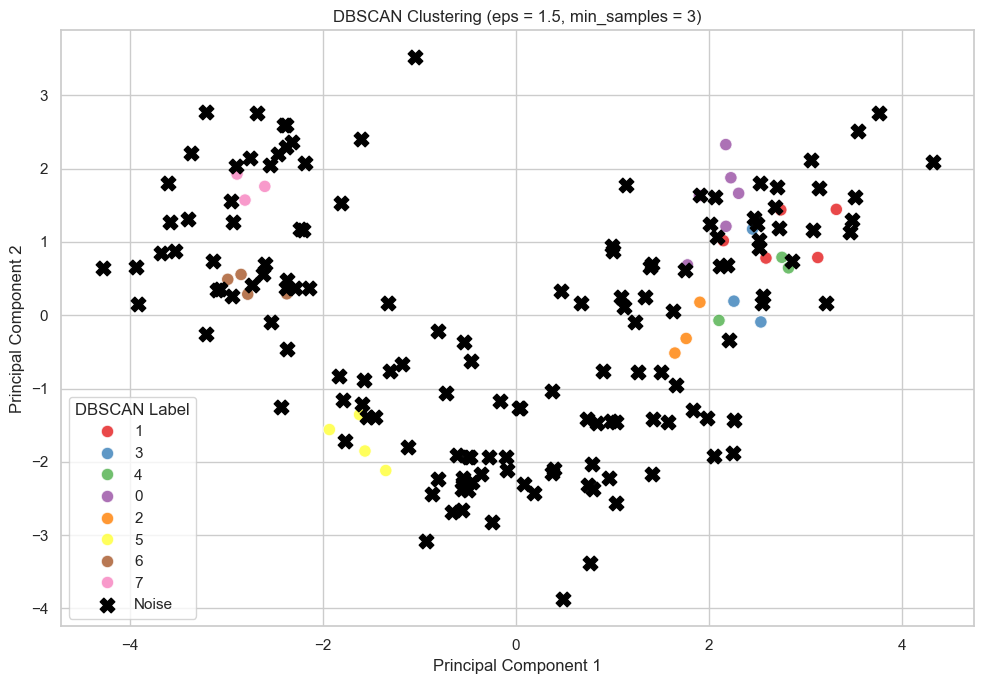

In [28]:
# Visualize the DBSCAN clusters and noise points
plt.figure(figsize=(10, 7))

# Plot observations assigned to regular clusters
sns.scatterplot(
    data=clustered_points,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="DBSCAN Cluster",
    palette="Set1",
    s=80,
    alpha=0.8
)

# Plot noise observations separately
plt.scatter(
    noise_points["Principal Component 1"],
    noise_points["Principal Component 2"],
    color="black",
    marker="X",
    s=110,
    label="Noise"
)

plt.title(
    f"DBSCAN Clustering "
    f"(eps = {best_eps}, min_samples = {best_min_samples})"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Label")
plt.tight_layout()
plt.show()

Step 3 Observations
DBSCAN was applied to all 13 standardized Wine dataset features. Different combinations of eps and min_samples were tested, and the combination with the highest valid Silhouette Score was selected.

The final model used eps = 1.5 and min_samples = 3. It produced 8 clusters and classified 147 observations as noise, leaving only 31 of the 178 observations in regular clusters.

The model achieved a Silhouette Score of 0.3311, a Homogeneity Score of 0.1892, and a Completeness Score of 0.2510. The Silhouette Score was calculated using only non-noise observations, while the other metrics included the noise label. Although the clustered observations were reasonably separated, the large number of noise points and low Homogeneity and Completeness Scores indicate that the model did not represent the overall class structure well.

The PCA plot displayed the DBSCAN clusters and highlighted noise points with black X markers. Some overlap may remain because the plot shows only two principal components, while DBSCAN used all 13 standardized features.

Step 4: Analysis and Insights
This section compares the clustering results produced by Agglomerative Hierarchical Clustering and DBSCAN. The comparison considers the number of clusters, evaluation metrics, treatment of noise, and visual patterns observed in the PCA scatter plots. It also examines how the selected parameters influenced each algorithm and discusses the strengths and weaknesses observed during the lab.

In [29]:
# Calculate additional metrics for Hierarchical Clustering
hierarchical_homogeneity = homogeneity_score(
    y,
    hierarchical_labels
)

hierarchical_completeness = completeness_score(
    y,
    hierarchical_labels
)

print(
    "Hierarchical Silhouette Score:",
    f"{best_silhouette_score:.4f}"
)

print(
    "Hierarchical Homogeneity Score:",
    f"{hierarchical_homogeneity:.4f}"
)

print(
    "Hierarchical Completeness Score:",
    f"{hierarchical_completeness:.4f}"
)

Hierarchical Silhouette Score: 0.2774
Hierarchical Homogeneity Score: 0.7904
Hierarchical Completeness Score: 0.7825


4.1 Comparison of Clustering Results
The selected Hierarchical Clustering and DBSCAN models are compared using their cluster counts, noise counts, Silhouette Scores, Homogeneity Scores, and Completeness Scores.

In [30]:
# Create a comparison of the selected clustering models
clustering_comparison_df = pd.DataFrame({
    "Algorithm": [
        "Hierarchical Clustering",
        "DBSCAN"
    ],
    "Number of Clusters": [
        best_n_clusters,
        dbscan_cluster_count
    ],
    "Noise Points": [
        0,
        dbscan_noise_count
    ],
    "Silhouette Score": [
        best_silhouette_score,
        dbscan_silhouette
    ],
    "Homogeneity Score": [
        hierarchical_homogeneity,
        dbscan_homogeneity
    ],
    "Completeness Score": [
        hierarchical_completeness,
        dbscan_completeness
    ]
})

clustering_comparison_df.round(4)

,Algorithm,Number of Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,Hierarchical Clustering,3,0,0.2774,0.7904,0.7825
1,DBSCAN,8,147,0.3311,0.1892,0.2510


In [31]:
# Summarize the parameters selected for each algorithm
print("Selected Hierarchical Clustering parameters:")
print(f"  Number of clusters: {best_n_clusters}")
print("  Linkage method: ward")
print("  Distance measure: euclidean")

print("\nSelected DBSCAN parameters:")
print(f"  eps: {best_eps}")
print(f"  min_samples: {best_min_samples}")
print(f"  Number of clusters: {dbscan_cluster_count}")
print(f"  Noise points: {dbscan_noise_count}")

Selected Hierarchical Clustering parameters:
  Number of clusters: 3
  Linkage method: ward
  Distance measure: euclidean

Selected DBSCAN parameters:
  eps: 1.5
  min_samples: 3
  Number of clusters: 8
  Noise points: 147


In [32]:
clustering_comparison_df.round(4)

,Algorithm,Number of Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,Hierarchical Clustering,3,0,0.2774,0.7904,0.7825
1,DBSCAN,8,147,0.3311,0.1892,0.2510


In [33]:
print("Hierarchical clusters:", best_n_clusters)
print("DBSCAN eps:", best_eps)
print("DBSCAN min_samples:", best_min_samples)
print("DBSCAN clusters:", dbscan_cluster_count)
print("DBSCAN noise points:", dbscan_noise_count)

Hierarchical clusters: 3
DBSCAN eps: 1.5
DBSCAN min_samples: 3
DBSCAN clusters: 8
DBSCAN noise points: 147


4.2 Comparison of Hierarchical Clustering and DBSCAN
Agglomerative Hierarchical Clustering formed three clusters and assigned all 178 observations to a cluster. In comparison, DBSCAN formed eight non-noise clusters but classified 147 observations as noise. As a result, only 31 observations were assigned to regular DBSCAN clusters. This indicates that the selected DBSCAN parameters imposed a restrictive density requirement on the standardized Wine dataset.

Hierarchical Clustering produced a Silhouette Score of 0.2774, a Homogeneity Score of 0.7904, and a Completeness Score of 0.7825. DBSCAN produced a higher Silhouette Score of 0.3311, but substantially lower Homogeneity and Completeness Scores of 0.1892 and 0.2510, respectively.

The DBSCAN Silhouette Score should be interpreted cautiously because it was calculated using only the 31 non-noise observations. In contrast, the Hierarchical Silhouette Score was calculated using all 178 observations. The higher DBSCAN score therefore indicates that its small number of clustered observations were relatively well separated, but it does not demonstrate effective clustering of the dataset as a whole.

Hierarchical Clustering produced much stronger Homogeneity and Completeness Scores. Its Homogeneity Score of 0.7904 indicates that its clusters generally contained observations from the same known wine class. Its Completeness Score of 0.7825 indicates that observations belonging to the same known class were generally assigned to the same cluster. DBSCAN's much lower external evaluation scores indicate that its eight clusters and noise category did not correspond closely to the three known wine classes.

Overall, Hierarchical Clustering produced the more useful and representative clustering result. Although DBSCAN achieved the higher Silhouette Score among its non-noise observations, it excluded most of the dataset as noise and showed weak agreement with the known class structure.

4.3 Influence of Parameter Selection
For Agglomerative Hierarchical Clustering, values of n_clusters from two through six were tested. Three clusters produced the highest Silhouette Score of 0.2774 among the tested values. Selecting fewer clusters would have combined observations into broader groups, while selecting more clusters would have divided the dataset into smaller groups. The selected value also corresponded to the three known classes in the Wine dataset, although those labels were not used to fit the model.

Ward linkage was used to minimize increases in within-cluster variance as groups were merged. Because this method relies on Euclidean distance, standardization was important. Without standardization, features with larger numerical ranges could have exerted disproportionate influence on the clustering result.

DBSCAN was more sensitive to its parameter settings. The selected combination used eps = 1.5 and min_samples = 3. The relatively small eps value created narrow neighborhoods in the 13-dimensional standardized feature space. Consequently, many observations did not have enough nearby neighbors to be connected to a dense region. This helps explain why DBSCAN classified 147 observations as noise.

The low min_samples value of three made it comparatively easy for a small group to qualify as a cluster. When combined with the restrictive eps value, this produced eight small clusters instead of a few broad clusters. Increasing eps would generally connect more observations, reduce the number of noise points, and potentially merge some of the eight clusters. Increasing min_samples, without also adjusting eps, would impose a stricter density requirement and could cause even more observations to be classified as noise.

Thus, n_clusters directly controlled the final partition produced by Hierarchical Clustering, while eps and min_samples jointly controlled DBSCAN's neighborhood size, density requirement, cluster formation, and noise identification.

4.4 Strengths and Weaknesses
Agglomerative Hierarchical Clustering
A major strength of Hierarchical Clustering was its ability to produce a complete and interpretable partition of the Wine dataset. Every observation was assigned to one of three clusters, and the dendrogram showed how observations and smaller groups were progressively merged. The model also produced relatively strong Homogeneity and Completeness Scores, indicating meaningful agreement with the known wine classes.

A limitation was that the number of clusters had to be selected in advance. The final result therefore depended on the tested values and the criterion used to select the cluster count. Hierarchical Clustering also lacked a built-in noise category, so every observation was assigned to a cluster, including observations that might have been unusual or poorly matched to a group.

DBSCAN
A strength of DBSCAN was that it did not require the number of clusters to be specified in advance. It also explicitly identified potential outliers through the noise label. The non-noise observations produced a Silhouette Score of 0.3311, suggesting that the small dense groups found by DBSCAN had reasonable internal cohesion and separation.

However, DBSCAN's main weakness in this experiment was its sensitivity to parameter selection. With eps = 1.5 and min_samples = 3, it classified 147 of the 178 observations as noise. This means that approximately 82.6% of the dataset was excluded from regular clusters. The remaining 31 observations were separated into eight clusters, indicating that the selected parameters produced a highly fragmented solution.

DBSCAN also achieved low Homogeneity and Completeness Scores, showing that its assignments did not align well with the known wine classes. Although detecting noise can be valuable, identifying most of the dataset as noise limited the usefulness of the selected model for describing the Wine dataset's overall structure

4.5 Conclusion
Agglomerative Hierarchical Clustering produced the stronger overall clustering result for the standardized Wine dataset. It formed three clusters, assigned all observations, and achieved Homogeneity and Completeness Scores of 0.7904 and 0.7825. These results indicate that its clusters corresponded reasonably well to the known wine-class structure.

DBSCAN produced a higher Silhouette Score of 0.3311 compared with 0.2774 for Hierarchical Clustering. However, the DBSCAN score was based only on the 31 non-noise observations. DBSCAN classified the other 147 observations as noise and achieved substantially lower Homogeneity and Completeness Scores.

Therefore, the higher DBSCAN Silhouette Score does not outweigh its limited coverage and weak correspondence with the known classes. Hierarchical Clustering provided a more complete, balanced, and representative description of the dataset. DBSCAN still demonstrated its ability to identify small dense groups and possible outliers, but its performance also showed that density-based clustering requires careful parameter tuning, particularly when applied to standardized high-dimensional data.